# Phase 1: House 1 raw REFIT inspection and cleaning

This notebook walks through the House 1 cleaning pipeline step by step. All logic lives in
[`run_cleaning.py`](run_cleaning.py) and the timestamp audit in [`final_tz_audit.py`](final_tz_audit.py); the notebook
imports them, so the notebook and the script use identical code. The written report is [`RESULTS.md`](RESULTS.md) and
the data notes are in [`DATA.md`](DATA.md).

- **Inputs (read only):** `Data/REFIT_RAW_081116/RAW_House1_Part1.csv` and `RAW_House1_Part2.csv`.
- **Outputs:** `outputs/tables/phase1/`, `outputs/figures/phase1/`, `Data/processed/phase1/`. They are written only in
  the last section, and only if every validation assertion passes.
- Phases 2 to 4 do **not** use these outputs; they use the official REFIT cleaned files.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

here = Path.cwd()
sys.path.insert(0, str(here if (here / "run_cleaning.py").exists() else here / "phase1"))
import run_cleaning as rc
import final_tz_audit as audit

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
res = rc.build(verbose=True)   # every step runs in memory; nothing is written yet

Loaded Part 1 (4,377,877 rows) and Part 2 (4,140,886 rows)


Part 1: canonical UTC built; repeated local hours: [{'date': '2013-10-27', 'rows': 1199, 'resolution': 'resolved by file order', 'rows_removed': 0}]


Part 2: canonical UTC built; repeated local hours: [{'date': '2014-10-26', 'rows': 986, 'resolution': 'unresolvable - rows removed', 'rows_removed': 986}]


Combined series: 6,552,571 unique UTC seconds


Built in 19.1s; assertions passed: 37/37


## 1 · Raw files

Two files cover House 1. Part 1 comes from the first logging system and Part 2 from the second. They overlap for
about three months in 2014.

In [2]:
display(res["t01_inventory"])

,File,Size_MB,Total_Rows,Start_Time_Local,End_Time_Local,Start_UTC,End_UTC,Duplicate_Unix_Rows,Raw_Unix_Backward_Steps,Canonical_UTC_Backward_Steps
0,RAW_House1_Part1.csv,232.27,4377877,2013-10-09 14:06:17,2014-10-01 01:27:07,2013-10-09 13:06:17,2014-10-01 00:27:07,1004404,1,0
1,RAW_House1_Part2.csv,228.55,4140886,2014-06-27 21:57:50,2015-07-10 11:56:32,2014-06-27 20:57:49,2015-07-10 10:56:32,14755,0,0


### What the `Time` and `Unix` columns mean

The check below compares `Unix` with the `Time` text read as if it were UTC. On every row the two agree to within
one second, so `Unix` carries no extra information: it is simply the `Time` value converted as though it were UTC.

In [3]:
for p, d in res["raw"].items():
    naive = pd.to_datetime(d["Time"]).astype("int64") // 10**9
    print(f"Part {p}: Unix - naive(Time) value counts:", (d["Unix"] - naive).value_counts().to_dict())

Part 1: Unix - naive(Time) value counts: {0: 2243876, -1: 2134001}
Part 2: Unix - naive(Time) value counts: {0: 2122044, -1: 2018842}


## 2 · Timestamps: the raw clock is the UK wall clock

The evidence is in three tables:

1. **Clock-change signatures (table 07).** At every UK clock change, the raw `Time` behaves like a UK wall clock.
   On 27 Oct 2013 Part 1 goes back from 01:59:59 to 01:00:01. On 30 Mar 2014 and 29 Mar 2015 the clock jumps
   forward from about 01:00 to 02:00. On 26 Oct 2014 Part 2's 01:00 hour holds roughly twice the normal number of
   rows: both passes through the repeated hour are merged into one sorted block.
2. **Part 1 vs Part 2 overlap (table 08, last rows).** In summer 2014 both files line up at lag 0 and not at
   ±60 min, so they share one clock.
3. **Official REFIT cleaned file (table 08).** On the canonical UTC axis the official House 1 file agrees with raw
   Part 1 in every month, both BST and GMT. It also agrees with Part 2 in GMT months, but sits exactly +60 min
   later in Part 2's BST months.

> **Assumption — canonical UTC:** `Time` is Europe/London local time, so canonical UTC = `Unix` − 3600 s during BST
> and `Unix` − 0 s during GMT. The 2013 repeated hour is assigned by file order: rows before the backward step are
> BST and rows after it are GMT.

> **Limitation — removed hour:** the repeated hour on 26 Oct 2014 (Part 2) is interleaved and cannot be split into
> its BST and GMT copies, so its rows are removed. In UTC this is a 2-hour hole (00:00–02:00 UTC).

In [4]:
display(res["t07_clock_changes"])

,Part,Date,Change,Rows_00_03_Local,Largest_Local_Step_From,Largest_Local_Step_To,Largest_Local_Step_s,Largest_Canonical_UTC_Step_s,Canonical_UTC_Backward_Steps,Ambiguous_Rows,Rows_Removed,Treatment
0,1,2013-10-27,autumn (clock back),2399.0,2013-10-27 01:59:59,2013-10-27 01:00:01,-3598.0,15.0,0.0,1199.0,0.0,resolved by file order
1,1,2014-03-30,spring (clock forward),1200.0,2014-03-30 00:59:58,2014-03-30 02:00:02,3604.0,13.0,0.0,0.0,0.0,local clock jumps forward; canonical UTC continuous (no outage)
2,2,2014-10-26,autumn (clock back),2055.0,2014-10-26 00:04:56,2014-10-26 00:05:10,14.0,7205.0,0.0,986.0,986.0,unresolvable - rows removed
3,2,2015-03-29,spring (clock forward),1079.0,2015-03-29 00:59:54,2015-03-29 02:00:01,3607.0,18.0,0.0,0.0,0.0,local clock jumps forward; canonical UTC continuous (no outage)
4,1->2,2014-09-27,Part 1 to Part 2 handoff,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Part 1 rows with UTC <= 2014-09-27 13:51:12 UTC, Part 2 after (= 2014-09-27 14:51:12 UK clock)"


In [5]:
aud = audit.run(norm=res["norm"], write=False)
display(aud["t08"])

,Comparison,Period,Clock_Regime,Best_Lag_Min,Corr_Best,Corr_Lag0,Corr_Lag_Plus60,Corr_Lag_Minus60,Minutes
0,Official CLEAN_House1 vs raw Part 1 (canonical UTC),2013-10,BST,0,0.999,0.999,0.254,0.254,31610
1,Official CLEAN_House1 vs raw Part 1 (stored Unix),2013-10,BST,-60,0.652,0.616,0.213,0.652,31456
2,Official CLEAN_House1 vs raw Part 1 (canonical UTC),2013-11,GMT,0,0.999,0.999,0.199,0.198,40787
3,Official CLEAN_House1 vs raw Part 1 (stored Unix),2013-11,GMT,0,0.999,0.999,0.199,0.198,40787
4,Official CLEAN_House1 vs raw Part 1 (canonical UTC),2013-12,GMT,0,0.999,0.999,0.173,0.173,43292
5,Official CLEAN_House1 vs raw Part 1 (stored Unix),2013-12,GMT,0,0.999,0.999,0.173,0.173,43292
6,Official CLEAN_House1 vs raw Part 1 (canonical UTC),2014-01,GMT,0,0.999,0.999,0.197,0.197,32269
7,Official CLEAN_House1 vs raw Part 1 (stored Unix),2014-01,GMT,0,0.999,0.999,0.197,0.197,32269
8,Official CLEAN_House1 vs raw Part 1 (canonical UTC),2014-03,GMT,0,1.000,1.000,0.366,0.365,36280
9,Official CLEAN_House1 vs raw Part 1 (stored Unix),2014-03,GMT,0,0.944,0.944,0.358,0.423,36214


> **Finding — official REFIT file:** the official `CLEAN_House1.csv` is consistent with our canonical UTC for all of
> Part 1 and for Part 2's GMT months. In Part 2's BST months it appears to keep UK local time. The same local-clock
> signatures (an empty 01:00 UTC hour on 29 Mar 2015, a doubled 01:00 UTC hour on 26 Oct 2014) also appear in the
> official files of the houses used in Phases 2–4 (table 15). This notebook does not change those phases; the
> point is reported in `RESULTS.md`.

In [6]:
display(aud["t15"])

,House,Date,Change,Rows_23h_prev_day,Rows_00h_UTC,Rows_01h_UTC,Rows_02h_UTC,Signature
0,1,2013-10-27,autumn,0,600,881,597,doubled 01:00 UTC hour (local-clock repeated hour)
1,1,2014-03-30,spring,843,0,600,600,empty 00:00 UTC hour
2,1,2014-10-26,autumn,534,534,986,535,doubled 01:00 UTC hour (local-clock repeated hour)
3,1,2015-03-29,spring,536,542,0,537,empty 01:00 UTC hour (local-clock spring jump)
4,2,2013-10-27,autumn,0,0,0,0,no data
5,2,2014-03-30,spring,859,0,600,592,empty 00:00 UTC hour
6,2,2014-10-26,autumn,544,543,1057,541,doubled 01:00 UTC hour (local-clock repeated hour)
7,2,2015-03-29,spring,538,536,0,535,empty 01:00 UTC hour (local-clock spring jump)
8,5,2013-10-27,autumn,0,598,839,600,doubled 01:00 UTC hour (local-clock repeated hour)
9,5,2014-03-30,spring,944,0,542,593,empty 00:00 UTC hour


### Relative drift between the two logger clocks

In the overlap, daily cross-correlation shows Part 1's clock slowly falling behind Part 2's. It then snaps back,
which looks like periodic re-synchronisation.

> **Limitation — clock drift:** there is no independent reference clock, so we cannot tell which logger is right.
> No drift correction is applied. Part 1 timestamps in summer 2014 may be off by a few minutes, and Part 1's
> accuracy before Part 2 started (Oct 2013 to Jun 2014) cannot be checked at all.

In [7]:
t09 = aud["t09"]
print("Days compared:", len(t09))
print("Part 1 minus Part 2 clock (minutes), days per value:", t09["Part1_Minus_Part2_Clock_Min"].value_counts().sort_index().to_dict())
display(t09[t09["Part1_Minus_Part2_Clock_Min"] == t09["Part1_Minus_Part2_Clock_Min"].min()])

Days compared: 87
Part 1 minus Part 2 clock (minutes), days per value: {-7: 1, -6: 3, -5: 3, -4: 4, -3: 3, -2: 9, -1: 18, 0: 46}


,Date,Part1_Minus_Part2_Clock_Min,Corr_Best,Corr_Lag0,Minutes
40,2014-08-07,-7,0.894,0.187,1439


## 3 · Data-quality overview and physical limits

Gaps are counted on the canonical UTC axis. The stored Unix axis also shows the two artificial 1-hour jumps at the
spring clock changes, which are clock artefacts rather than outages.

> **Assumption — physical limits:** an appliance reading above 4,000 W, an aggregate reading above 25,000 W, or any
> negative reading is a sensor error and is set to missing. This is the project's own rule. The official REFIT
> cleaning replaces IAM spikes above 4,000 W with 0 W; marking them missing is the more conservative choice.

> **Limitation:** some implausible readings sit below the 4 kW cap and are not removed. The maximum fridge (Appliance1)
> minute in table 04 is an example.

In [8]:
display(res["t02_anomalies"])
display(res["t03_outliers"])

,Metric,Part1,Part2,Combined
0,Total Rows,4377877.00,4140886.00,8518763.00
1,Missing Values (NaN cells across all channels),0.00,5284083.00,5284083.00
2,Duplicate Unix Timestamps (rows),1004404.00,14755.00,1019159.00
3,Rows Removed: Unresolvable Repeated Local Hour,0.00,986.00,986.00
4,"Gaps > 2 Minutes (120s), canonical UTC",592.00,122.00,714.00
5,"Gaps > 15 Minutes (900s), canonical UTC",56.00,28.00,84.00
6,"Gaps > 1 Hour (3600s), canonical UTC",13.00,19.00,32.00
7,"Gaps > 24 Hours (86400s), canonical UTC",3.00,10.00,13.00
8,"Gaps > 1 Hour (3600s), raw Unix as stored",14.00,19.00,33.00
9,"Maximum Outage Duration (Hours), canonical UTC",998.45,207.57,998.45


,Channel,Appliance_Name,Physical_Limit_Watts,Part1_Max_Watts,Part1_Negative_Count,Part1_Above_Limit_Count,Part2_Max_Watts,Part2_Negative_Count,Part2_Above_Limit_Count,Total_Flagged_Glitches
0,Aggregate,Mains Whole-House,25000.0,24000.0,0,0,29159.0,0,3,3
1,Appliance1,Fridge,4000.0,69629.0,0,662,76677.0,0,184,846
2,Appliance2,Freezer (1),4000.0,98301.0,0,18,66685.0,0,22,40
3,Appliance3,Freezer (2),4000.0,32751.0,0,38,73725.0,0,80,118
4,Appliance4,Washer Dryer,4000.0,98301.0,0,2014,98301.0,0,71,2085
5,Appliance5,Washing Machine,4000.0,32767.0,0,156,73725.0,0,65,221
6,Appliance6,Dishwasher,4000.0,14336.0,0,24,37610.0,0,12,36
7,Appliance7,Computer,4000.0,98299.0,0,3,73725.0,0,371,374
8,Appliance8,Television Site,4000.0,65549.0,0,88,98301.0,0,91,179
9,Appliance9,Electric Heater,4000.0,65535.0,0,35,32737.0,0,15,50


## 4 · Part 1 to Part 2 handoff

The pipeline uses Part 1 up to the handoff instant (2014-09-27 14:51:12 on the UK clock, which is 13:51:12 UTC) and
Part 2 after it. An earlier version of this notebook justified this instant by a Part 1 failure. The comparison below
does not support that: around the handoff both files show the same values, including the same flat channels and the
same spikes.

> **Assumption — handoff:** the handoff instant is kept as a project choice, expressed in canonical UTC. Within the
> overlap no instant is empirically better; at this instant the two clocks agree to within the daily resolution of
> table 09.

In [9]:
display(res["t12_handoff_agreement"])

,Period,Channel,Minutes_Both,Pct_Minutes_Within_5W,Part1_Distinct_Values,Part2_Distinct_Values,Part1_Max_W,Part2_Max_W
0,7 days before handoff,Aggregate,10014,85.7,1035,1052,10894.3,10868.571429
1,7 days before handoff,Appliance1,10014,98.6,88,98,453.9,240.285714
2,7 days before handoff,Appliance2,10014,97.0,81,93,437.3,234.500000
3,7 days before handoff,Appliance3,10014,97.7,88,101,337.9,213.000000
4,7 days before handoff,Appliance4,9989,99.8,33,32,2591.4,2583.833333
5,7 days before handoff,Appliance5,9856,98.0,170,169,2388.2,2388.000000
6,7 days before handoff,Appliance6,10014,99.6,56,58,2317.9,2312.625000
7,7 days before handoff,Appliance7,10014,99.6,38,38,46.6,45.285714
8,7 days before handoff,Appliance8,10014,99.4,49,50,52.6,54.800000
9,7 days before handoff,Appliance9,12,100.0,1,1,1.0,1.000000


## 5 · Same-second rows, hold limits and Part 2's asynchronous telemetry

- **Several rows in one UTC second** are merged per channel by keeping the last non-missing reading. The check
  confirms that no (second, channel) reading is lost in the merge.
- **Hold limit (forward fill).** Each reading is held until the channel's next reading, but for no more than 60 s
  (aggregate, washer-dryer, washing machine, dishwasher) or 120 s (fridge, freezers, computer, TV, heater).
- **Part 2** writes NaN for a channel that did not report in that packet. Holding the last reading bridges these
  short reporting gaps.

> **Assumption — hold limits:** the 60/120 s limits are this project's conservative policy. They are not REFIT's
> method (REFIT forward-fills without a limit). Time beyond the limit is left missing rather than imputed.

> **Limitation:** in Part 1, an unavailable sensor was recorded as 0 W (REFIT readme), so a Part 1 zero cannot be told
> apart from a real 0 W reading.

In [10]:
display(res["t11_cleaning_checks"])

,Area,Metric,Value,Note
0,De-duplication,Part 1: rows used / unique UTC seconds,4328936 / 3334050,
1,De-duplication,Part 1: seconds holding more than one row,820268,
2,De-duplication,"Part 1: (second, channel) cells with a reading before / after merge",33338258 / 33338258,equal = no complementary reading lost
3,De-duplication,Part 2: rows used / unique UTC seconds,3230675 / 3218521,
4,De-duplication,Part 2: seconds holding more than one row,12154,
5,De-duplication,"Part 2: (second, channel) cells with a reading before / after merge",28960673 / 28960673,equal = no complementary reading lost
6,Hold limit,Aggregate: short gaps 60-900 s left partly unfilled (count; minutes not filled),1434; 4623.6,decided by the hold limit
7,Hold limit,"Aggregate: gaps > 900 s, i.e. outages (count; hours missing)",75; 1959.8,missing under any short hold limit
8,Part 2 telemetry,Aggregate: Part 2 rows without a reading (%); median / 99th pct gap between readings (s),4.2; 7 / 15,
9,Hold limit,Appliance1: short gaps 120-900 s left partly unfilled (count; minutes not filled),1084; 4897.7,decided by the hold limit


## 6 · 1-minute resampling

Each held interval is split exactly at minute boundaries. A minute's value is its energy divided by the time
covered, and it is kept only if at least 30 s of the minute is covered. Table 05 compares this with a plain
arithmetic mean of the readings that start in the minute.

In [11]:
display(res["t05_resampling"])

,Channel,Appliance_Name,Minutes_Compared,Mean_Absolute_Diff_W,P95_Absolute_Diff_W,P99_Absolute_Diff_W,Max_Absolute_Diff_W
0,Aggregate,Mains Whole-House,797473,9.720,50.329,210.167,3111.748
1,Appliance1,Fridge,794859,0.147,0.150,3.352,460.650
2,Appliance2,Freezer (1),794085,0.263,0.333,4.883,758.150
3,Appliance3,Freezer (2),796088,0.223,0.200,6.100,496.250
4,Appliance4,Washer Dryer,797103,0.063,0.000,0.000,834.583
5,Appliance5,Washing Machine,787061,0.439,0.000,6.497,1218.333
6,Appliance6,Dishwasher,797415,0.197,0.000,0.000,1348.350
7,Appliance7,Computer,797535,0.034,0.100,0.867,176.250
8,Appliance8,Television Site,795808,0.064,0.342,1.233,1314.133
9,Appliance9,Electric Heater,701748,0.964,0.367,31.259,1088.400


## 7 · Cleaned dataset availability and outages

Outages are kept as missing values. Table 13 lists every Aggregate gap longer than 1 hour. The 2-hour hole on
26 Oct 2014 is the removed repeated hour from section 2.

In [12]:
display(res["t04_availability"])
display(res["t13_outages"])

,Channel,Appliance_Name,Total_Minutes,Valid_Minutes,Missing_Minutes,Availability_Pct,Zero_Pct,Active_Pct,Mean_Active_Power_W,Max_Power_W
0,Aggregate,Mains Whole-House,920033,798013,122020,86.74,0.00,86.74,479.2,23971.3
1,Appliance1,Fridge,920033,797117,122916,86.64,65.14,21.50,71.1,3072.0
2,Appliance2,Freezer (1),920033,796421,123612,86.56,55.15,31.42,45.8,2099.0
3,Appliance3,Freezer (2),920033,797348,122685,86.67,50.42,36.24,69.6,564.2
4,Appliance4,Washer Dryer,920033,797653,122380,86.70,86.26,0.43,378.1,2688.9
5,Appliance5,Washing Machine,920033,788647,131386,85.72,83.66,2.06,452.0,2461.6
6,Appliance6,Dishwasher,920033,797949,122084,86.73,85.86,0.87,1125.2,2383.4
7,Appliance7,Computer,920033,798760,121273,86.82,76.72,10.10,21.4,2049.0
8,Appliance8,Television Site,920033,797653,122380,86.70,70.51,16.19,31.3,1314.1
9,Appliance9,Electric Heater,920033,703664,216369,76.48,0.00,76.48,76.9,2087.1


,Start_UTC,End_UTC,Duration_Hours,Source_Part
0,2013-10-09 19:11:06,2013-10-09 20:23:49,1.21,1
1,2013-11-07 10:03:19,2013-11-08 11:42:13,25.65,1
2,2013-12-16 10:01:19,2013-12-16 11:06:09,1.08,1
3,2013-12-18 18:18:02,2013-12-18 19:40:34,1.38,1
4,2014-01-24 01:56:25,2014-03-06 16:23:19,998.45,1
5,2014-07-07 02:46:51,2014-07-07 08:32:49,5.77,1
6,2014-07-13 23:39:37,2014-07-14 00:53:57,1.24,1
7,2014-07-21 10:01:35,2014-07-21 12:08:18,2.11,1
8,2014-07-30 13:15:20,2014-07-30 14:15:23,1.00,1
9,2014-08-01 16:07:07,2014-08-02 12:59:45,20.88,1


## 8 · Energy validation

For each window, the raw reference is the exact integral of the held raw signal over the half-open UTC window
[start, end), under the same hold limits. The cleaned value is the sum of 1-minute means × 60 s over the minutes
that were kept. Two further columns separate out the effect of the 30-second coverage rule and of the hold limit.
Full-record rows check every channel over the whole dataset, not just the three example windows.

> **Assumption — tolerance:** a window passes if cleaned and raw energy differ by at most
> `rc.ENERGY_TOLERANCE_PCT` percent.

> **Limitation:** "energy preserved" here means the resampling keeps the energy of the *observed* signal. Energy
> drawn while the logger was silent beyond the hold limit is not recovered. The `Hold_Limit_Effect_Pct` column shows
> how much more energy would appear if readings were held without a limit. On full-record rows that figure mostly
> reflects long outages being filled, so it is not a resampling error.

In [13]:
print("Tolerance (%):", rc.ENERGY_TOLERANCE_PCT)
display(res["t06_energy"])

Tolerance (%): 1.0


,Channel,Window,Window_UTC,Raw_Coverage_Pct,Raw_Held_kWh,Cleaned_kWh,Pct_Diff,Cleaned_Coverage_Weighted_kWh,Pct_Diff_Coverage_Weighted,Energy_In_Dropped_Minutes_kWh,Like_For_Like_Residual_Ws,Minutes_Kept,Minutes_Partial_Dropped,Raw_No_Hold_Limit_kWh,Hold_Limit_Effect_Pct,Within_Tolerance
0,Aggregate,48 h household load,"[2013-11-15 00:00:00, 2013-11-17 00:00:00)",98.84,37.3554,37.3542,-0.003,37.3207,-0.093,0.0347,0.0,2847,6,37.6567,-0.800,True
1,Appliance5,Washing-machine cycle,"[2013-10-23 05:45:00, 2013-10-23 08:00:00)",91.11,0.5356,0.5356,0.000,0.5356,0.000,0.0000,0.0,124,0,0.5356,0.000,True
2,Appliance1,12 h fridge cycling,"[2013-10-12 00:00:00, 2013-10-12 12:00:00)",96.88,0.1480,0.1476,-0.301,0.1476,-0.301,0.0004,0.0,697,3,0.1616,-8.443,True
3,Aggregate,Full record,"[2013-10-09 13:06:00, 2015-07-10 10:59:00)",86.72,6371.2190,6373.7565,0.040,6369.8677,-0.021,1.3513,0.0,798013,717,7977.3867,-20.134,True
4,Appliance1,Full record,"[2013-10-09 13:06:00, 2015-07-10 10:59:00)",86.63,234.3439,234.3628,0.008,234.2605,-0.036,0.0834,0.0,797117,947,329.0153,-28.774,True
5,Appliance2,Full record,"[2013-10-09 13:06:00, 2015-07-10 10:59:00)",86.56,220.5578,220.5813,0.011,220.4460,-0.051,0.1118,0.0,796421,995,289.0172,-23.687,True
6,Appliance3,Full record,"[2013-10-09 13:06:00, 2015-07-10 10:59:00)",86.66,387.0266,387.0265,-0.000,386.9483,-0.020,0.0783,0.0,797348,603,421.3149,-8.138,True
7,Appliance4,Full record,"[2013-10-09 13:06:00, 2015-07-10 10:59:00)",86.68,25.1212,25.1423,0.084,25.0924,-0.115,0.0288,0.0,797653,770,25.7961,-2.616,True
8,Appliance5,Full record,"[2013-10-09 13:06:00, 2015-07-10 10:59:00)",85.67,142.7880,142.8752,0.061,142.6690,-0.083,0.1190,0.0,788647,2207,146.7897,-2.726,True
9,Appliance6,Full record,"[2013-10-09 13:06:00, 2015-07-10 10:59:00)",86.71,149.8022,149.8265,0.016,149.7984,-0.003,0.0038,0.0,797949,724,150.4090,-0.403,True


### Why the original washing-machine check showed a large difference

Table 10 reproduces the original calculation and then changes one thing at a time. Step A is the original result.
Step B uses the same UTC interval on both sides; the original raw window started one hour earlier than the
cleaned window. Step C holds each raw reading forward instead of weighting it by the time since the previous
row. Step D excludes the end minute. Step E is the revised method. Step F is a sensitivity run with no hold limit.

In [14]:
d = res["t10_energy_decomposition"]
display(d)
wm = d[d.Channel == "Appliance5"].set_index("Step")["Pct_Diff"]
print(f"Washing machine: original {wm['A']:+.2f}% -> aligned window {wm['B']:+.2f}% -> forward hold {wm['C']:+.2f}% "
      f"-> revised {wm['E']:+.2f}%; effect of removing the hold limit: {wm['F'] - wm['E']:+.2f} percentage points")

,Channel,Window,Step,What_Changed,Raw_kWh,Cleaned_kWh,Diff_kWh,Pct_Diff
0,Aggregate,48 h household load,A,"Original calculation: raw rows in the original raw window (inclusive), weighted by time since previous row; cleaned ...",37.2977,37.3228,0.0252,0.07
1,Aggregate,48 h household load,B,"A, with the raw window moved to the same UTC interval as the cleaned window",37.2977,37.3228,0.0252,0.07
2,Aggregate,48 h household load,C,"B, with each raw reading held until the next row (as the resampler does)",37.3551,37.3228,-0.0322,-0.09
3,Aggregate,48 h household load,D,"C, with half-open windows [start, end) on both sides (end minute excluded)",37.3551,37.3196,-0.0355,-0.09
4,Aggregate,48 h household load,E,Revised method: exact held-interval integral (channel hold limit) vs revised 1-minute means x 60 s,37.3554,37.3542,-0.0012,-0.00
5,Aggregate,48 h household load,F,Sensitivity: raw held with no hold limit (until next reading) vs revised 1-minute means x 60 s,37.6567,37.3542,-0.3025,-0.80
6,Appliance5,Washing-machine cycle,A,"Original calculation: raw rows in the original raw window (inclusive), weighted by time since previous row; cleaned ...",0.4913,0.5355,0.0441,8.99
7,Appliance5,Washing-machine cycle,B,"A, with the raw window moved to the same UTC interval as the cleaned window",0.5331,0.5355,0.0023,0.44
8,Appliance5,Washing-machine cycle,C,"B, with each raw reading held until the next row (as the resampler does)",0.5356,0.5355,-0.0002,-0.03
9,Appliance5,Washing-machine cycle,D,"C, with half-open windows [start, end) on both sides (end minute excluded)",0.5356,0.5355,-0.0002,-0.03


Washing machine: original +8.99% -> aligned window +0.44% -> forward hold -0.03% -> revised +0.00%; effect of removing the hold limit: +0.00 percentage points


## 9 · Validation assertions

These checks run before anything is written: timestamp ordering, clock-change handling, the handoff,
de-duplication, physical limits, minute coverage, outage preservation and exact energy conservation. If any of
them fails, nothing is written.

In [15]:
a = res["t14_assertions"]
print(f"{int(a.Passed.sum())}/{len(a)} assertions passed")
display(a)

37/37 assertions passed


,Check,Passed,Detail
0,Part 1: UTC offset is 0 or 3600 s on every row,True,"[np.int64(0), np.int64(3600)]"
1,Part 1: canonical UTC never decreases in file order,True,backward steps = 0
2,Part 1: every repeated local hour resolved or removed,True,"[{'date': '2013-10-27', 'rows': 1199, 'resolution': 'resolved by file order', 'rows_removed': 0}]"
3,Part 2: UTC offset is 0 or 3600 s on every row,True,"[np.int64(0), np.int64(3600)]"
4,Part 2: canonical UTC never decreases in file order,True,backward steps = 0
5,Part 2: every repeated local hour resolved or removed,True,"[{'date': '2014-10-26', 'rows': 986, 'resolution': 'unresolvable - rows removed', 'rows_removed': 986}]"
6,Spring clock changes: canonical UTC step < 60 s,True,"[{'Part': 1, 'Date': '2014-03-30', 'Largest_Local_Step_s': 3604.0, 'Largest_Canonical_UTC_Step_s': 13.0}, {'Part': 2..."
7,Autumn clock changes: no backward step in canonical UTC,True,
8,Combined index unique and strictly increasing,True,
9,"Handoff: Part 1 ends at or before, Part 2 starts after the handoff",True,1411825869 <= 1411825872 < 1411825878


## 10 · Write outputs and figures

Saved outputs/tables/phase1/01_house1_raw_file_inventory.csv
Saved outputs/tables/phase1/02_data_quality_anomalies_summary.csv
Saved outputs/tables/phase1/03_outlier_flagging_summary.csv
Saved outputs/tables/phase1/04_cleaned_dataset_availability_summary.csv
Saved outputs/tables/phase1/05_arithmetic_vs_timeweighted_comparison.csv
Saved outputs/tables/phase1/06_energy_preservation_comparison.csv
Saved outputs/tables/phase1/07_timestamp_clock_changes.csv
Saved outputs/tables/phase1/10_energy_validation_decomposition.csv
Saved outputs/tables/phase1/11_cleaning_decision_checks.csv
Saved outputs/tables/phase1/12_handoff_overlap_agreement.csv
Saved outputs/tables/phase1/13_aggregate_outages_over_1h.csv
Saved outputs/tables/phase1/14_pipeline_assertions.csv
Saved Data/processed/phase1/house1_cleaned_1min.parquet
Saved Data/processed/phase1/house1_cleaned_1min.csv.gz
Saved outputs/figures/phase1/01_aggregate_power_before_after.png
Saved outputs/figures/phase1/02_washing_machine_before_after.pn

Saved outputs/tables/phase1/15_official_clean_dst_signatures.csv
Saved outputs/tables/phase1/08_timestamp_alignment_checks.csv
Saved outputs/tables/phase1/09_part1_part2_daily_clock_offset.csv


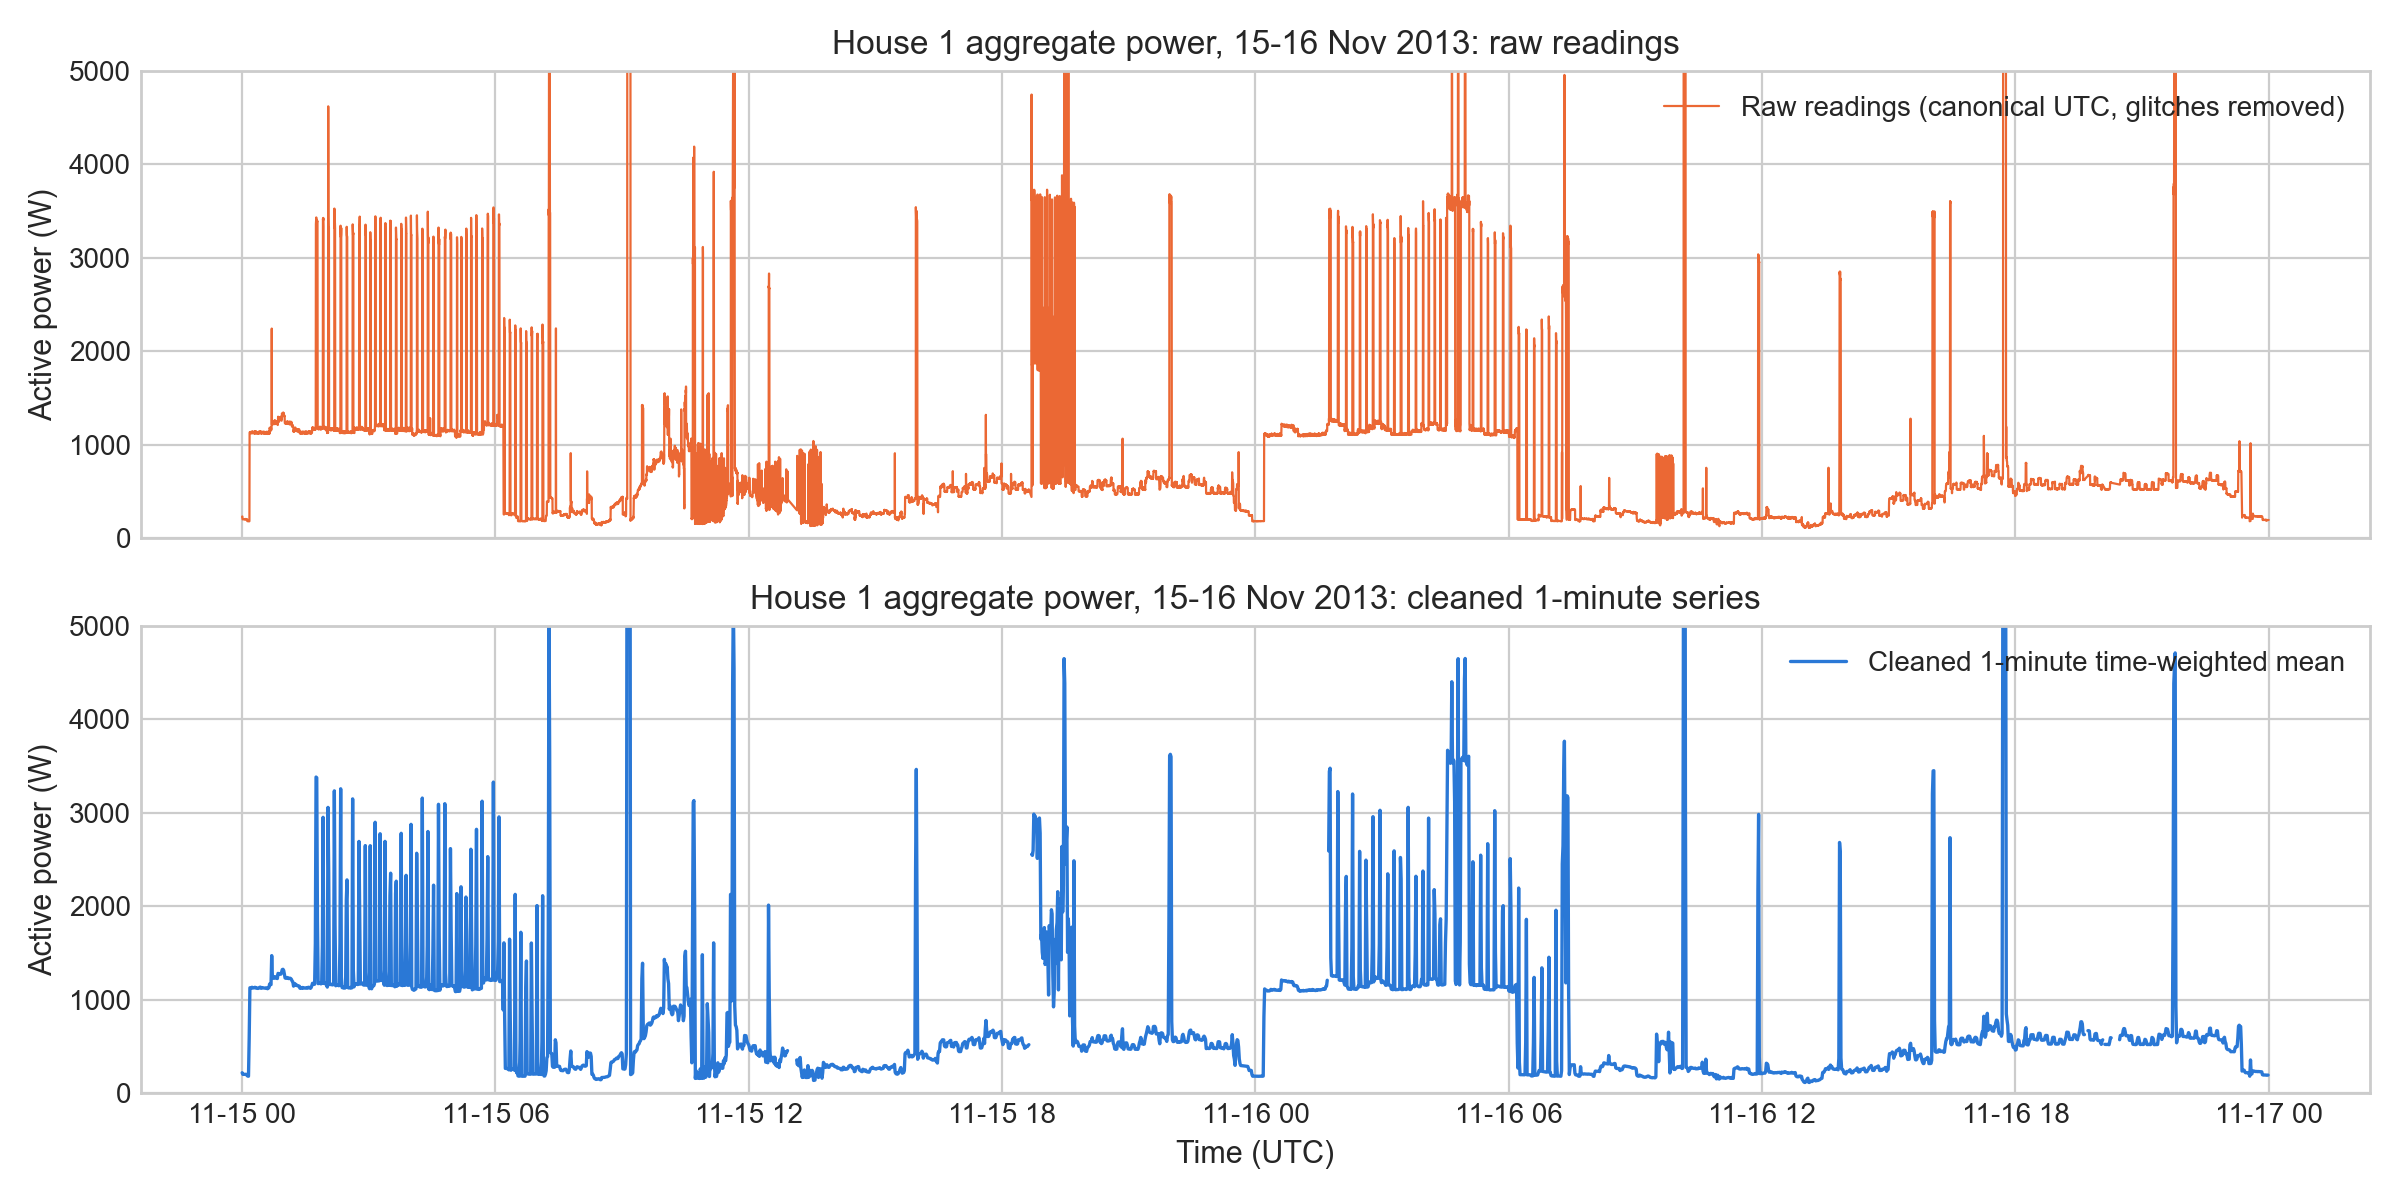

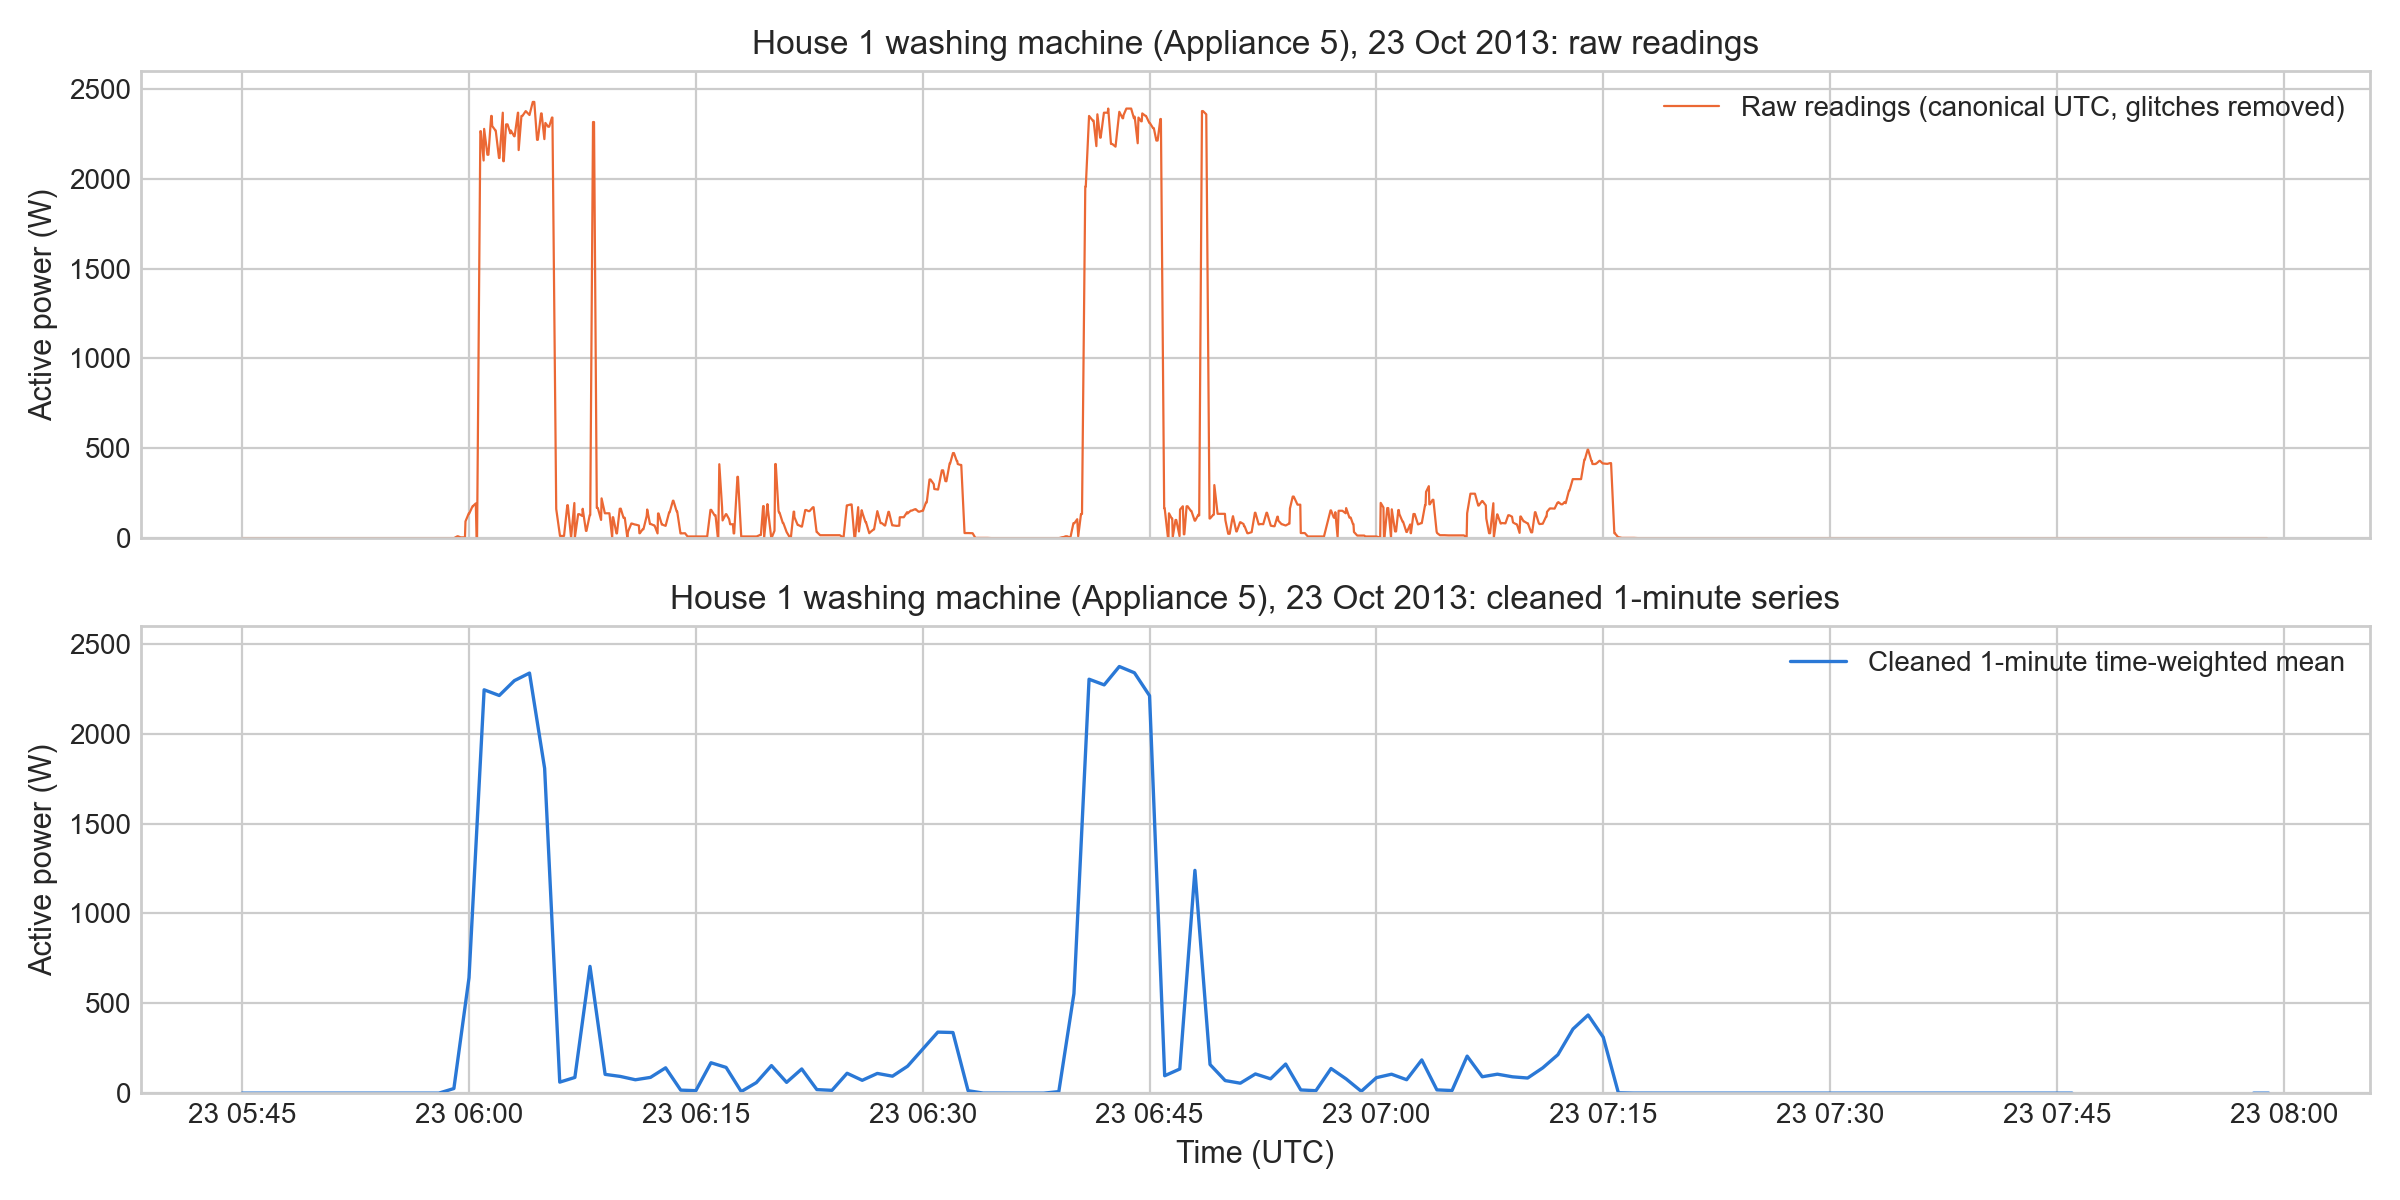

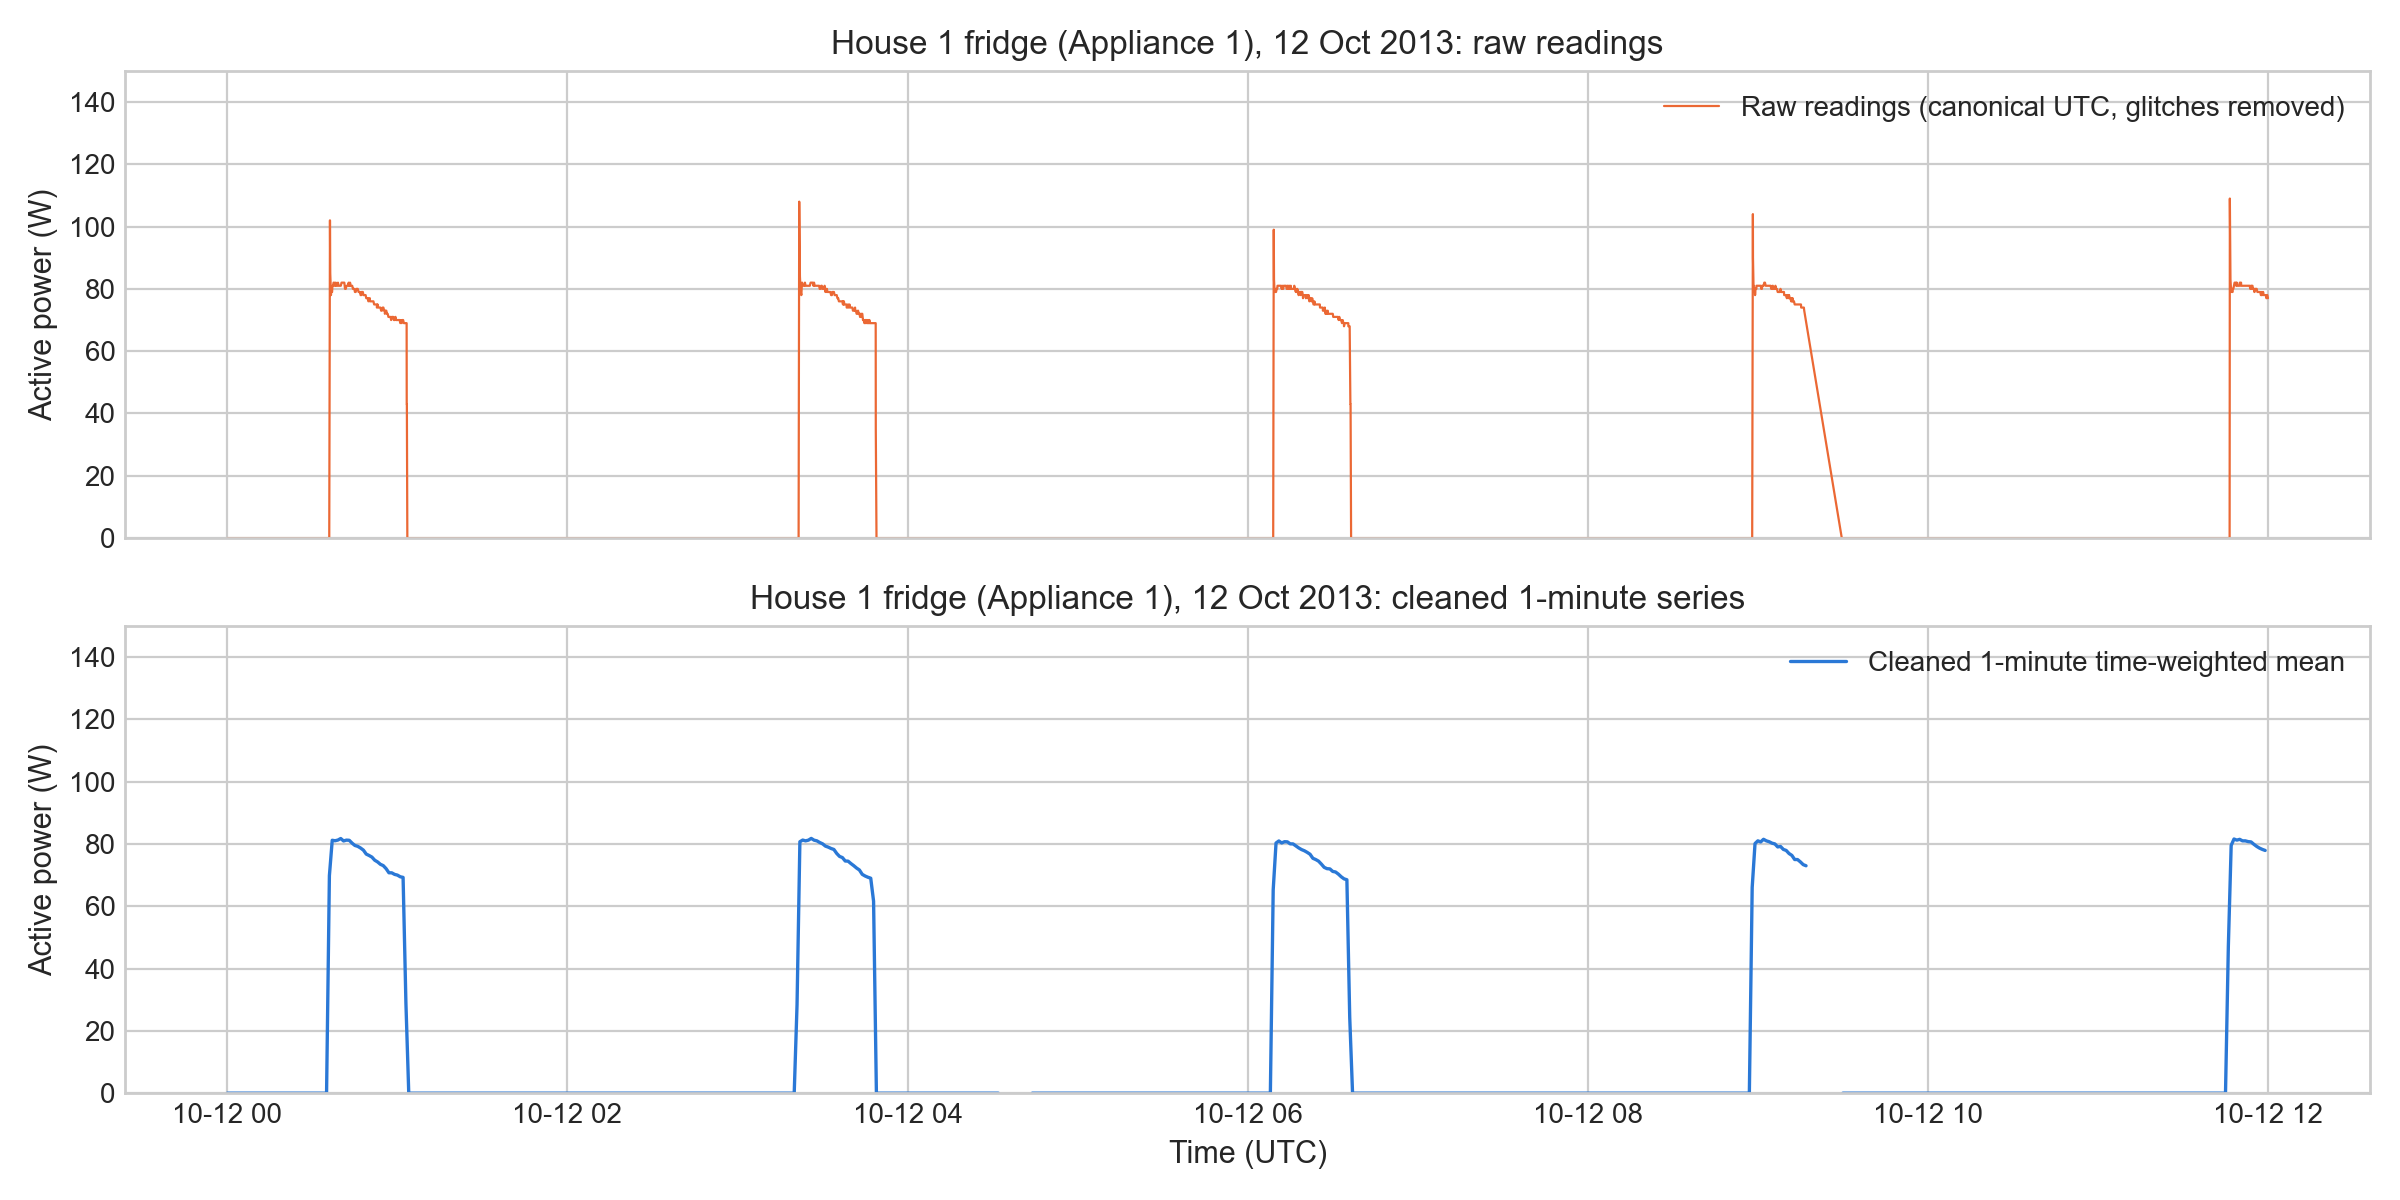

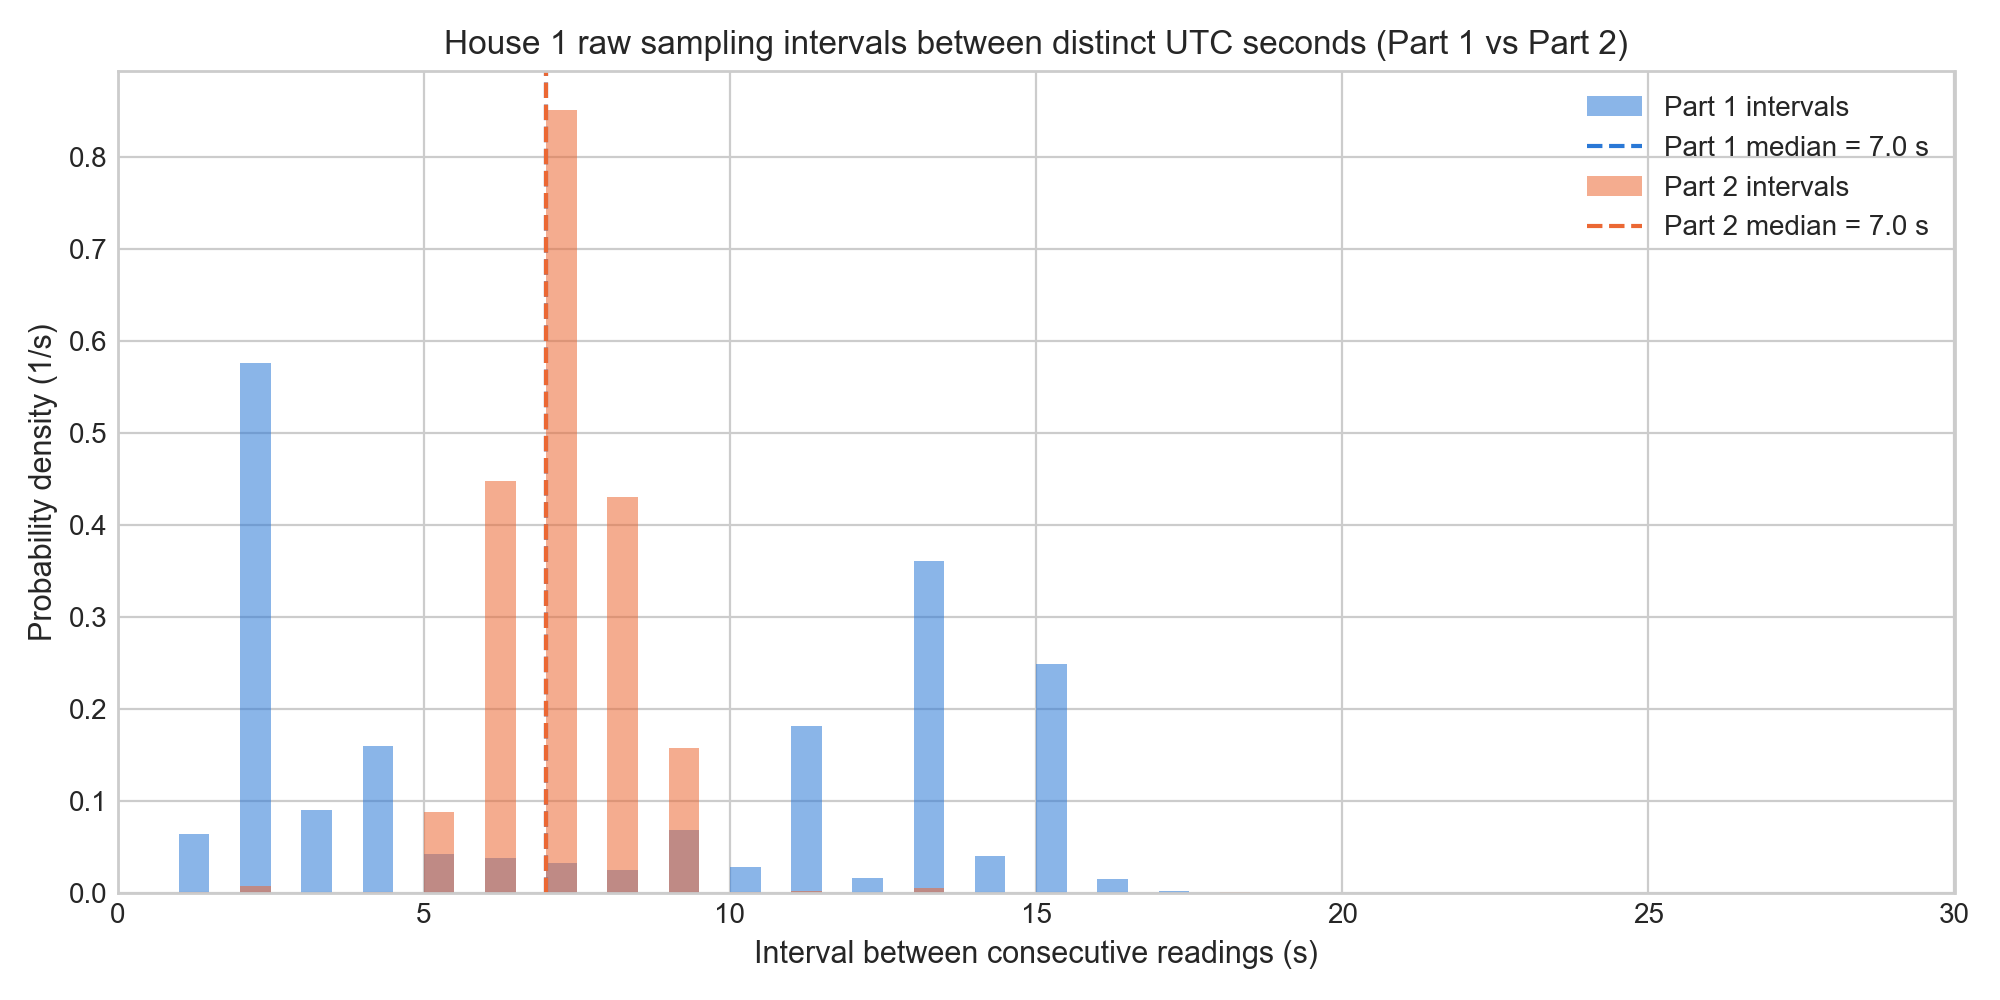

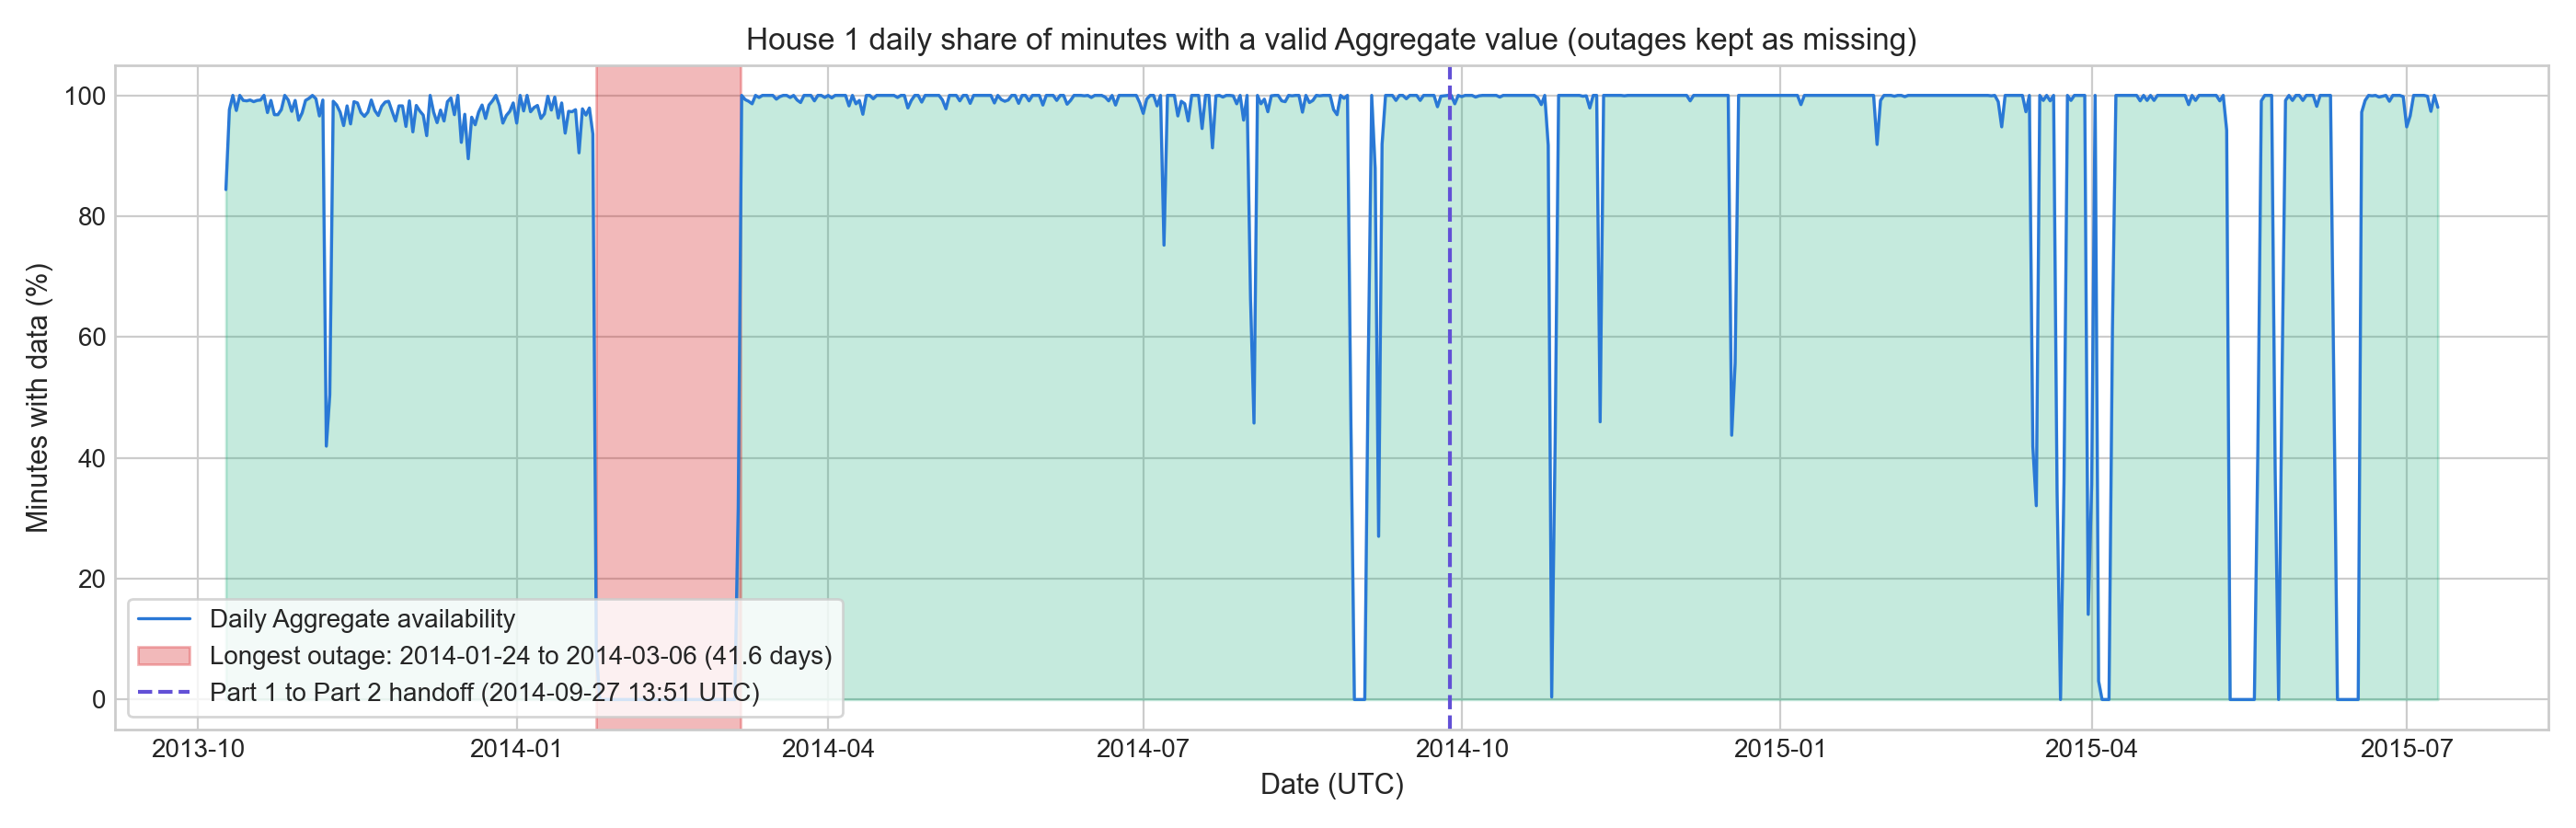

In [16]:
out = rc.write_outputs(res)                  # raises (and writes nothing) if any assertion failed
audit.run(norm=res["norm"])                  # tables 08, 09 and 15
for f in res["figs"]:
    display(Image(filename=str(f)))

In [17]:
print("\n".join(str(p.relative_to(rc.ROOT)) for p in sorted(rc.out_paths()["tables"].glob("*.csv"))))
print("\n".join(str(p.relative_to(rc.ROOT)) for p in res["figs"]))
print(out["final"].shape)
out["final"].head()

outputs/tables/phase1/01_house1_raw_file_inventory.csv
outputs/tables/phase1/02_data_quality_anomalies_summary.csv
outputs/tables/phase1/03_outlier_flagging_summary.csv
outputs/tables/phase1/04_cleaned_dataset_availability_summary.csv
outputs/tables/phase1/05_arithmetic_vs_timeweighted_comparison.csv
outputs/tables/phase1/06_energy_preservation_comparison.csv
outputs/tables/phase1/07_timestamp_clock_changes.csv
outputs/tables/phase1/08_timestamp_alignment_checks.csv
outputs/tables/phase1/09_part1_part2_daily_clock_offset.csv
outputs/tables/phase1/10_energy_validation_decomposition.csv
outputs/tables/phase1/11_cleaning_decision_checks.csv
outputs/tables/phase1/12_handoff_overlap_agreement.csv
outputs/tables/phase1/13_aggregate_outages_over_1h.csv
outputs/tables/phase1/14_pipeline_assertions.csv
outputs/tables/phase1/15_official_clean_dst_signatures.csv
outputs/figures/phase1/01_aggregate_power_before_after.png
outputs/figures/phase1/02_washing_machine_before_after.png
outputs/figures/ph

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 13:06:00,1381323960,529.581395,74.348837,0.0,68.674419,0.0,0.0,0.0,0.0,0.0,1.0
1,2013-10-09 13:07:00,1381324020,541.483333,73.800000,0.0,68.566667,0.0,0.0,0.0,0.0,0.0,1.0
2,2013-10-09 13:08:00,1381324080,575.450000,73.216667,0.0,43.750000,0.0,0.0,0.0,0.0,0.0,1.0
3,2013-10-09 13:09:00,1381324140,635.283333,72.766667,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
4,2013-10-09 13:10:00,1381324200,785.150000,72.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
